# Module 08 Lab - The Bias-Variance Tradeoff

**Objective:** To understand and visualize the concepts of **overfitting**, **underfitting**, and the **bias-variance tradeoff**, which are central to building models that generalize well to new data.

**In this lab, you will train models of varying complexity and plot their performance to see these concepts in action.**

## Part 1: Understanding the Concepts*   
**Underfitting (High Bias):** The model is **too simple** and fails to capture the underlying patterns in the data. It performs poorly on both the training data and the test data. It has high bias because it makes strong, incorrect assumptions about the data.*   

**Overfitting (High Variance):** The model is **too complex** and learns the ,training data too well, including the noise and random fluctuations. It performs exceptionally well on the training data but poorly on the test data because it has memorized the training set instead of learning the general pattern. It has high variance because its performance changes drastically with different training data.*   

**The Goal:** Find a model that is "just right"—complex enough to capture the true pattern but not so complex that it memorizes the noise. This is the **bias-variance tradeoff**.

## Part 2: Setup

To visualize this, we will create a synthetic (fake) dataset with a known pattern and some noise.

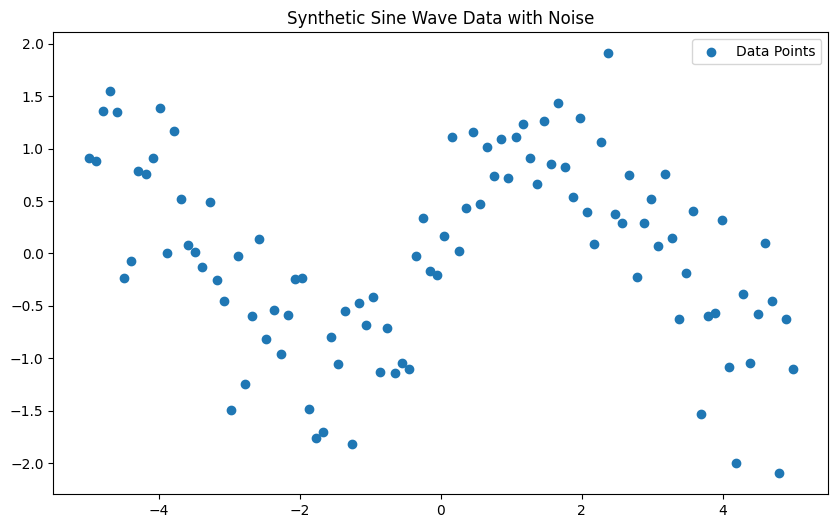

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import learning_curve

# Generate some synthetic datanp.random.seed(0)
X = np.linspace(-5, 5, 100)
y = np.sin(X) + np.random.normal(0, 0.5, 100)
X = X[:, np.newaxis]

# Plot the data to see the underlying sine wave pattern
plt.figure(figsize=(10, 6))
plt.scatter(X, y, label='Data Points')

plt.title('Synthetic Sine Wave Data with Noise')
plt.legend()
plt.show()

## Part 3: Modeling with Different Complexities

We will use **Polynomial Regression** to control model complexity. A polynomial of degree 1 is a simple straight line (underfitting). A polynomial of degree 15 is a very complex, wiggly line (overfitting).

**Your Task:** Train and visualize three models with different degrees (1, 4, and 15) to see underfitting, a good fit, and overfitting.

### Task 1: Train and Plot Models

**Your Task:** For each degree (1, 4, 15), create a polynomial regression model, train it, and plot its predictions against the original data.

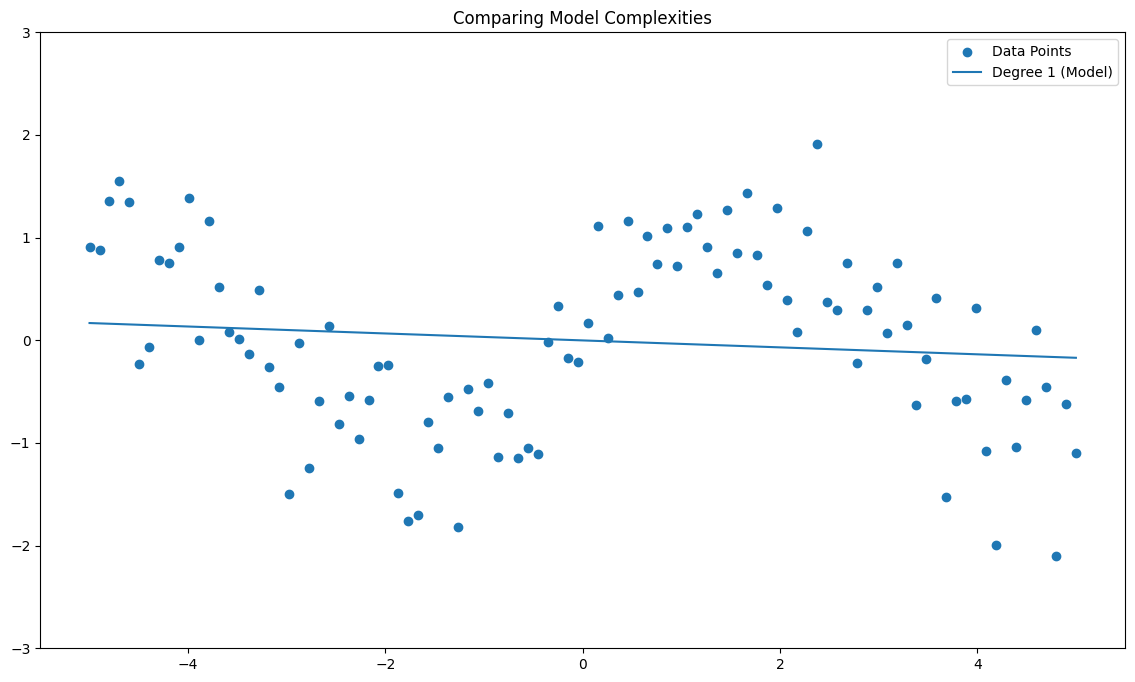

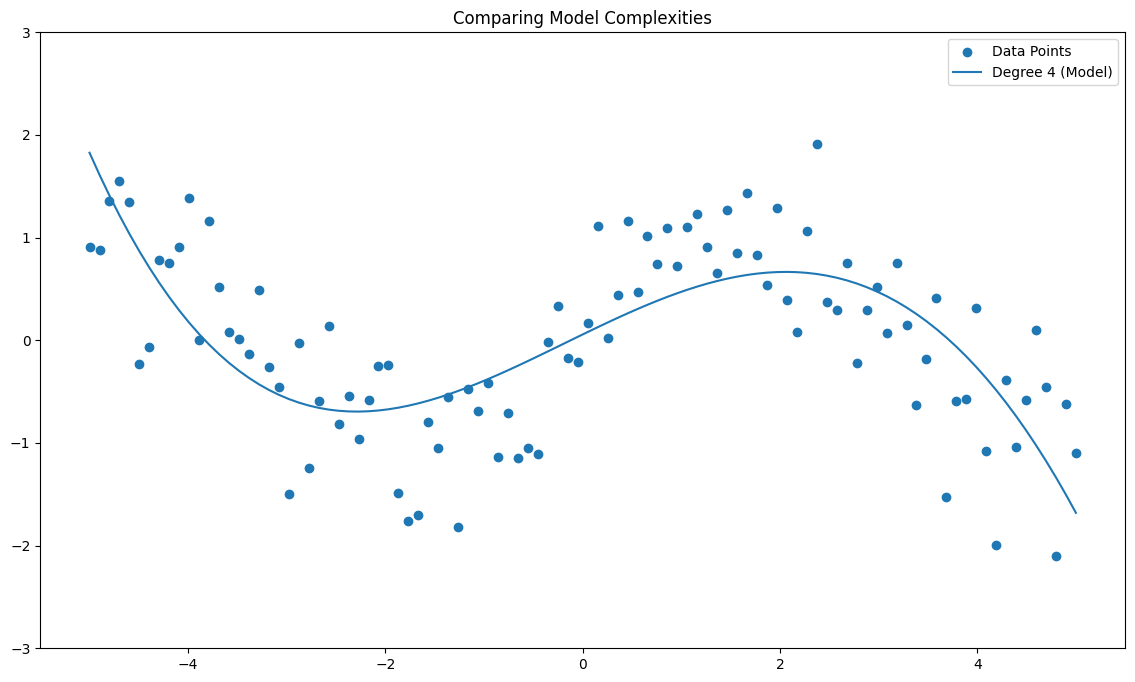

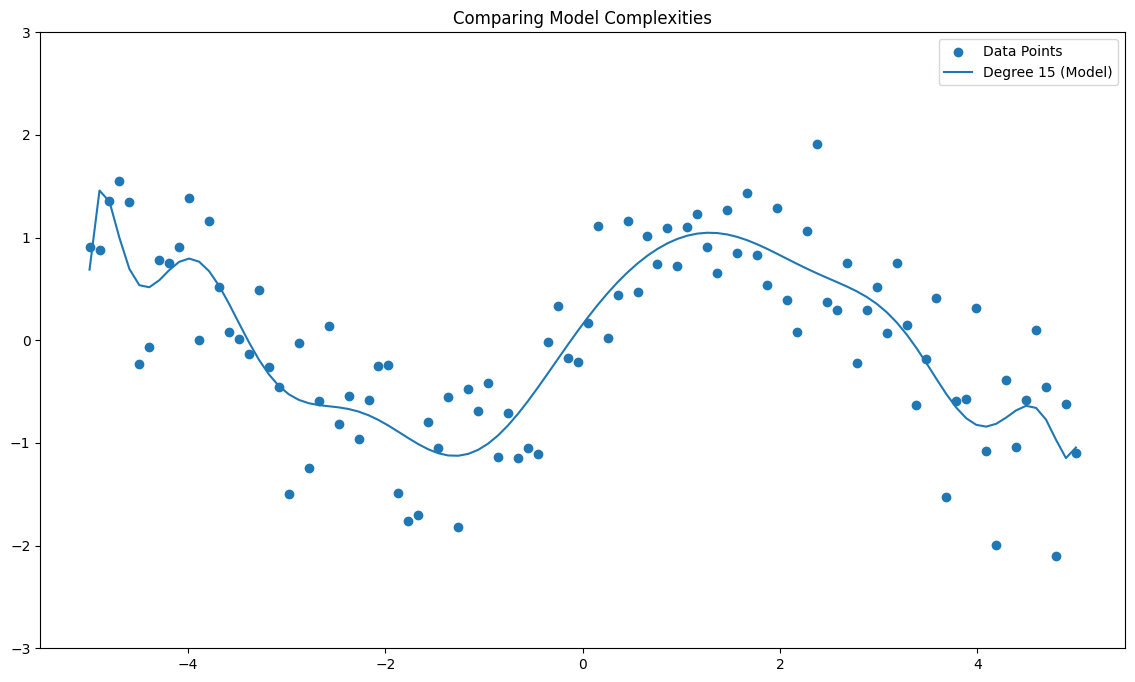

In [ ]:
# --- ENTER YOUR CODE HERE ---
# plt.figure(figsize=(14, 8))
# plt.scatter(X, y, label='Data Points')
degrees = [1, 4, 15]
for degree in degrees:
  plt.figure(figsize=(14, 8))
  plt.scatter(X, y, label='Data Points')
  # 1. Create a pipeline that adds polynomial features and then fits a linear regression model
  model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
  # 2. Train the model
  model.fit(X, y)
  # 3. Make predictions
  y_pred = model.predict(X)
  # 4. Plot the model's predictions
  plt.plot(X, y_pred, label=f'Degree {degree} (Model)')

  plt.legend()
  plt.title('Comparing Model Complexities')
  plt.ylim(-3, 3)
  plt.show()

## Part 4: Learning Curves
**Concept:** A **learning curve** is a powerful tool to diagnose bias and variance. It plots the model's performance (e.g., accuracy or error) on both the **training set** and the **validation set** as a function of the number of training samples.*   

**High Bias (Underfitting):** Both the training score and validation score will be low and will plateau quickly. The model is too simple to learn from more data.*   

**High Variance (Overfitting):** There will be a large gap between the high training score and the low validation score. The model memorized the training data but can't generalize.*   

**Just Right:** The training and validation scores will converge to a high value.

### Task 2: Plot Learning Curves

**Your Task:** Use the `learning_curve` function from scikit-learn to plot the learning curves for the underfit (degree 1) and overfit (degree 15) models.

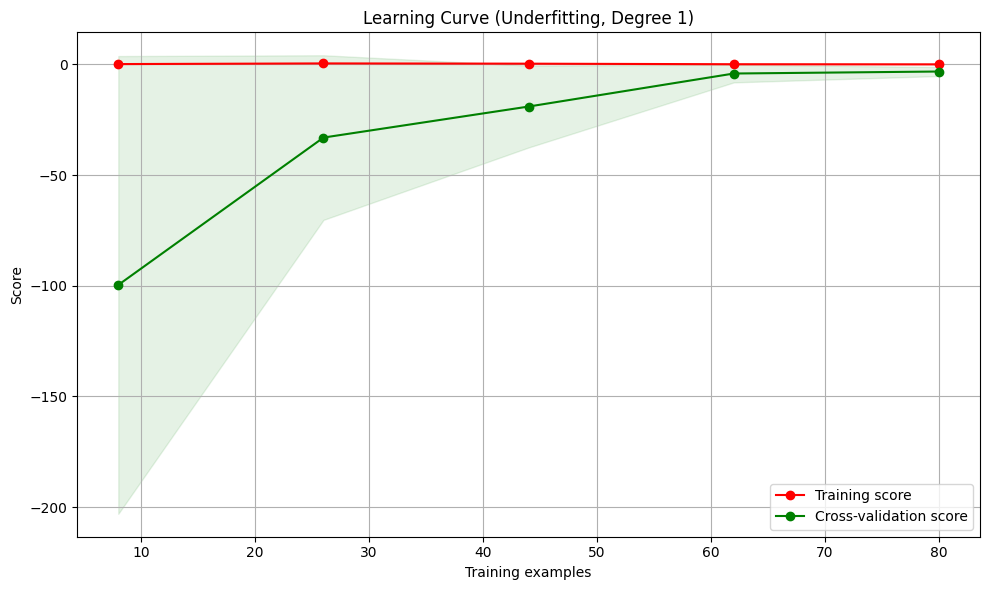

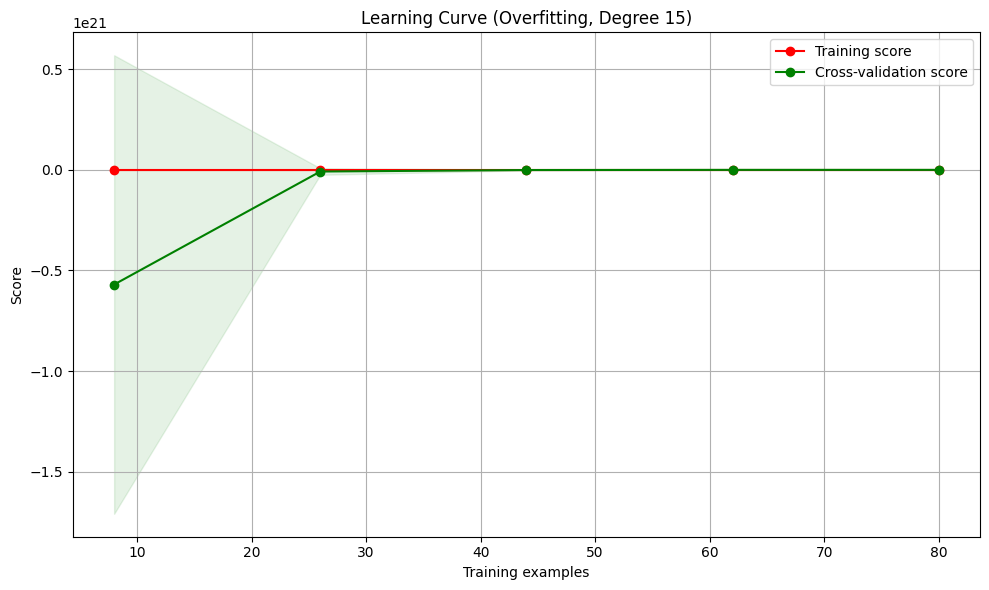

In [ ]:

def plot_learning_curve(estimator,title,X,y,ylim=None,cv=None,n_jobs=None,train_sizes=np.linspace(0.1, 1.0, 5)):
    plt.figure(figsize=(10, 6))
    plt.title(title)

    if ylim is not None:
        plt.ylim(*ylim)

    plt.xlabel("Training examples")
    plt.ylabel("Score")

    train_sizes, train_scores, test_scores = learning_curve(
        estimator,
        X,
        y,
        cv=cv,
        n_jobs=n_jobs,
        train_sizes=train_sizes
    )

    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)

    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)

    plt.grid()

    plt.fill_between(
        train_sizes,
        train_scores_mean - train_scores_std,
        train_scores_mean + train_scores_std,
        alpha=0.1,
        color="r"
    )

    plt.fill_between(
        train_sizes,
        test_scores_mean - test_scores_std,
        test_scores_mean + test_scores_std,
        alpha=0.1,
        color="g"
    )

    plt.plot(
        train_sizes,
        train_scores_mean,
        "o-",
        color="r",
        label="Training score"
    )

    plt.plot(
        train_sizes,
        test_scores_mean,
        "o-",
        color="g",
        label="Cross-validation score"
    )

    plt.legend(loc="best")
    plt.tight_layout()

    return plt


# Underfit model
underfit_model = make_pipeline(
    PolynomialFeatures(degree=1),
    LinearRegression()
)

plot_learning_curve(underfit_model,"Learning Curve (Underfitting, Degree 1)",X,y,cv=5)
plt.show()

# Overfit model
overfit_model = make_pipeline(
    PolynomialFeatures(degree=15),
    LinearRegression()
)

plot_learning_curve(overfit_model,"Learning Curve (Overfitting, Degree 15)",X,y,cv=5)
plt.show()

## 📝 Knowledge Check

**Instructions:** Answer the following questions in this markdown cell.

1.  **In the first plot of the three models, which model (degree 1, 4, or 15) is underfitting, which is overfitting, and which is a good fit? Explain your reasoning.**

2.  **Looking at the learning curve for the underfitting model, what do you observe about the training and cross-validation scores?** What does this tell you?

3.  **Looking at the learning curve for the overfitting model, what do you observe about the gap between the training and cross-validation scores?** What does this tell you?

**[ENTER YOUR ANSWERS HERE]**


**Answer One:**
  1. The 1st of the three is **Underfitting**; **Reasoning:** The graph does not at all map to the distribution of data on the graph
  2. The 3rd of the three is **Overfitting**; **Reasoning:** The graph follows the distribution of data points but zigzags around in the data set which demonstrates that the model is trying to predict specifics rather than generalizations.
  3. The 2nd of the three is **Good Fit**; **Reasoning:** The graphs line is smooth and follows the distribution of the datapoints on the graph
